In [1]:
%pip install yfinance pandas numpy matplotlib seaborn scipy sqlalchemy pymysql

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 629.9 kB/s eta 0:00:03
   ---------- ----------------------------- 0.5/2.0 MB 629.9 kB/s eta 0:00:03
   --------------- ------------------------ 0.8/2.0 MB 577.3 kB/s eta 0:00:03
   --------------- ------------------------ 0.8/2.0 MB 577.3 kB/s eta 0:00:03
   --------------------- ------------------ 1.0/2.0 MB 595.9 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/2.0 MB 595.9 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/2.0 MB 592.2 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/2.0 MB 592.2 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/2.0 MB 592.2 kB/s eta 0:00:02
   -------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import yfinance as yf
import pandas as pd
from pathlib import Path

# Define the stocks
tickers = {
    "RELIANCE.NS": "Reliance Industries",
    "HDFCBANK.NS": "HDFC Bank",
    "TCS.NS": "TCS",
    "INFY.NS": "Infosys",
    "ICICIBANK.NS": "ICICI Bank",
    "^NSEI": "Nifty 50"
}

# Create project directories
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Download five years of daily data
data = yf.download(
    list(tickers.keys()),
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False,
    group_by="ticker",
    threads=True
)

print("Download completed.")
print("Dataset shape:", data.shape)
print(data.head())

Download completed.
Dataset shape: (1236, 30)
Ticker          INFY.NS                                                  \
Price              Open         High          Low        Close   Volume   
Date                                                                      
2021-10-25  1499.858227  1506.564673  1469.504751  1487.229126  5905209   
2021-10-26  1502.606265  1517.148544  1490.172761  1497.026489  5871709   
2021-10-27  1501.771498  1523.782761  1494.785944  1519.213501  5090259   
2021-10-28  1510.778133  1515.523088  1486.789920  1497.202393  5329972   
2021-10-29  1492.896729  1504.846911  1459.550432  1465.437622  5875091   

Ticker     ICICIBANK.NS                                                ...  \
Price              Open        High         Low       Close    Volume  ...   
Date                                                                   ...   
2021-10-25   769.528164  833.976148  767.989131  809.639832  96124084  ...   
2021-10-26   797.135001  809.639833  791.

In [3]:
print("Available ticker symbols:")
print(data.columns.get_level_values(0).unique())

print("\nMissing values:")
print(data.isna().sum().head(20))

print("\nDate range:")
print(data.index.min(), "to", data.index.max())

Available ticker symbols:
Index(['INFY.NS', 'ICICIBANK.NS', 'HDFCBANK.NS', 'TCS.NS', '^NSEI',
       'RELIANCE.NS'],
      dtype='object', name='Ticker')

Missing values:
Ticker        Price 
INFY.NS       Open      0
              High      0
              Low       0
              Close     0
              Volume    0
ICICIBANK.NS  Open      0
              High      0
              Low       0
              Close     0
              Volume    0
HDFCBANK.NS   Open      0
              High      0
              Low       0
              Close     0
              Volume    0
TCS.NS        Open      0
              High      0
              Low       0
              Close     0
              Volume    0
dtype: int64

Date range:
2021-10-25 00:00:00 to 2026-10-23 00:00:00


In [4]:
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)

data.to_csv("data/raw/stock_market_raw.csv")

print("Raw stock market data saved successfully!")

Raw stock market data saved successfully!


In [5]:
import pandas as pd
from pathlib import Path

tickers = {
    "RELIANCE.NS": "Reliance Industries",
    "HDFCBANK.NS": "HDFC Bank",
    "TCS.NS": "TCS",
    "INFY.NS": "Infosys",
    "ICICIBANK.NS": "ICICI Bank",
    "^NSEI": "Nifty 50"
}

records = []

for ticker, company in tickers.items():

    try:
        stock = data[ticker].copy()

        if stock.empty:
            print(f"No data available for {ticker}")
            continue

        stock.columns.name = None
        stock = stock.reset_index()

        stock["Ticker"] = ticker
        stock["Company"] = company

        records.append(stock)

    except (KeyError, TypeError) as e:
        print(f"Could not process {ticker}: {e}")

if not records:
    raise ValueError(
        "No stock data was processed. Check the downloaded dataset."
    )

df = pd.concat(records, ignore_index=True)

# Standardise column names
df.columns = [
    str(col).strip().replace(" ", "_")
    for col in df.columns
]

# Remove duplicate stock-date records
df = df.drop_duplicates(subset=["Date", "Ticker"])

# Sort the data
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Cleaned dataset shape: (7416, 8)
        Date        Open        High         Low       Close      Volume  \
0 2021-10-25  790.748762  790.748762  755.094906  775.308105  16426766.0   
1 2021-10-26  772.032920  783.192293  770.325078  773.319641  12090656.0   
2 2021-10-27  773.319571  779.074747  766.090559  768.664001  13249642.0   
3 2021-10-28  772.032870  772.032870  742.625448  745.643372  17797750.0   
4 2021-10-29  743.958952  749.573736  729.921990  740.613464  12406874.0   

        Ticker    Company  
0  HDFCBANK.NS  HDFC Bank  
1  HDFCBANK.NS  HDFC Bank  
2  HDFCBANK.NS  HDFC Bank  
3  HDFCBANK.NS  HDFC Bank  
4  HDFCBANK.NS  HDFC Bank  
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Ticker', 'Company']


In [6]:
print("1. Dataset information")
df.info()

print("\n2. Missing values")
print(df.isna().sum())

print("\n3. Duplicate records")
print(df.duplicated(["Date", "Ticker"]).sum())

print("\n4. Date range")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\n5. Number of observations per stock")
print(df.groupby("Ticker").size())

print("\n6. Descriptive statistics")
print(df[["Open", "High", "Low", "Close", "Volume"]].describe())

1. Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7416 entries, 0 to 7415
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     7416 non-null   datetime64[ns]
 1   Open     7415 non-null   float64       
 2   High     7415 non-null   float64       
 3   Low      7415 non-null   float64       
 4   Close    7415 non-null   float64       
 5   Volume   7415 non-null   float64       
 6   Ticker   7416 non-null   object        
 7   Company  7416 non-null   object        
dtypes: datetime64[ns](1), float64(5), object(2)
memory usage: 463.6+ KB

2. Missing values
Date       0
Open       1
High       1
Low        1
Close      1
Volume     1
Ticker     0
Company    0
dtype: int64

3. Duplicate records
0

4. Date range
Start: 2021-10-25 00:00:00
End: 2026-10-23 00:00:00

5. Number of observations per stock
Ticker
HDFCBANK.NS     1236
ICICIBANK.NS    1236
INFY.NS         1236
RELIANCE.NS   

In [7]:
Path("data/processed").mkdir(parents=True, exist_ok=True)

df.to_csv(
    "data/processed/stock_market_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

Cleaned dataset saved successfully!
Total rows: 7416
Total columns: 8


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(
    "data/processed/stock_market_cleaned.csv",
    parse_dates=["Date"]
)

df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (7416, 8)
        Date        Open        High         Low       Close      Volume  \
0 2021-10-25  790.748762  790.748762  755.094906  775.308105  16426766.0   
1 2021-10-26  772.032920  783.192293  770.325078  773.319641  12090656.0   
2 2021-10-27  773.319571  779.074747  766.090559  768.664001  13249642.0   
3 2021-10-28  772.032870  772.032870  742.625448  745.643372  17797750.0   
4 2021-10-29  743.958952  749.573736  729.921990  740.613464  12406874.0   

        Ticker    Company  
0  HDFCBANK.NS  HDFC Bank  
1  HDFCBANK.NS  HDFC Bank  
2  HDFCBANK.NS  HDFC Bank  
3  HDFCBANK.NS  HDFC Bank  
4  HDFCBANK.NS  HDFC Bank  


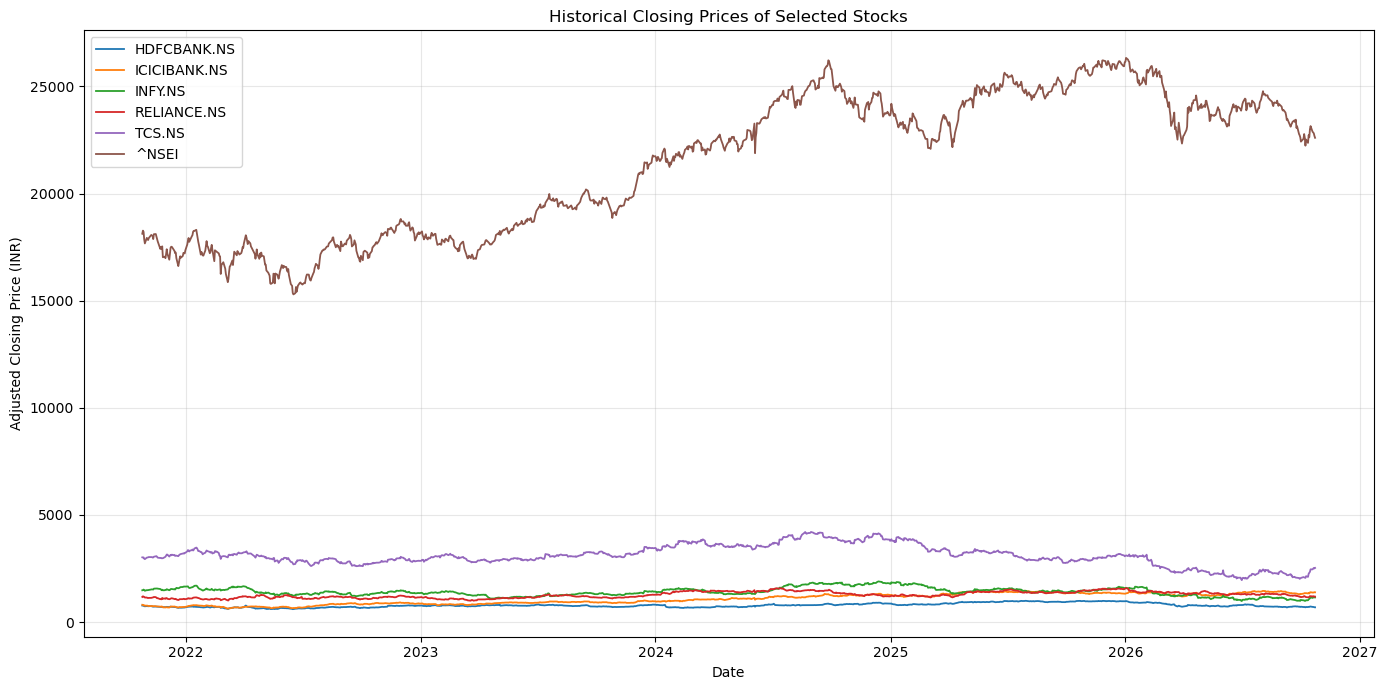

In [9]:
plt.figure(figsize=(14, 7))

for ticker in df["Ticker"].unique():
    stock = df[df["Ticker"] == ticker]
    
    plt.plot(
        stock["Date"],
        stock["Close"],
        label=ticker,
        linewidth=1.3
    )

plt.title("Historical Closing Prices of Selected Stocks")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

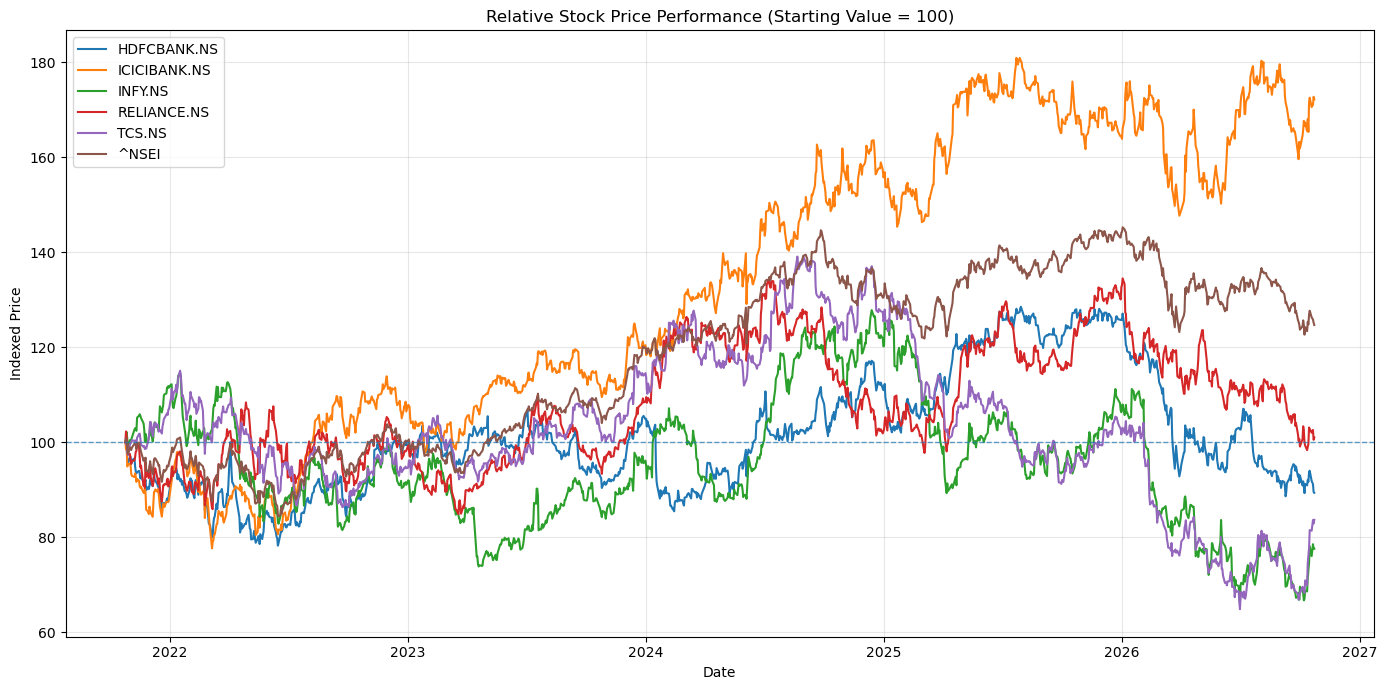

In [10]:
df["Indexed_Price"] = (
    df["Close"]
    / df.groupby("Ticker")["Close"].transform("first")
) * 100

plt.figure(figsize=(14, 7))

for ticker in df["Ticker"].unique():
    stock = df[df["Ticker"] == ticker]
    
    plt.plot(
        stock["Date"],
        stock["Indexed_Price"],
        label=ticker,
        linewidth=1.5
    )

plt.axhline(
    100,
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

plt.title("Relative Stock Price Performance (Starting Value = 100)")
plt.xlabel("Date")
plt.ylabel("Indexed Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Average Daily Trading Volume:
Ticker
HDFCBANK.NS     2.822067e+07
ICICIBANK.NS    1.402619e+07
RELIANCE.NS     1.331181e+07
INFY.NS         7.822756e+06
TCS.NS          2.655948e+06
^NSEI           3.070176e+05
Name: Volume, dtype: float64


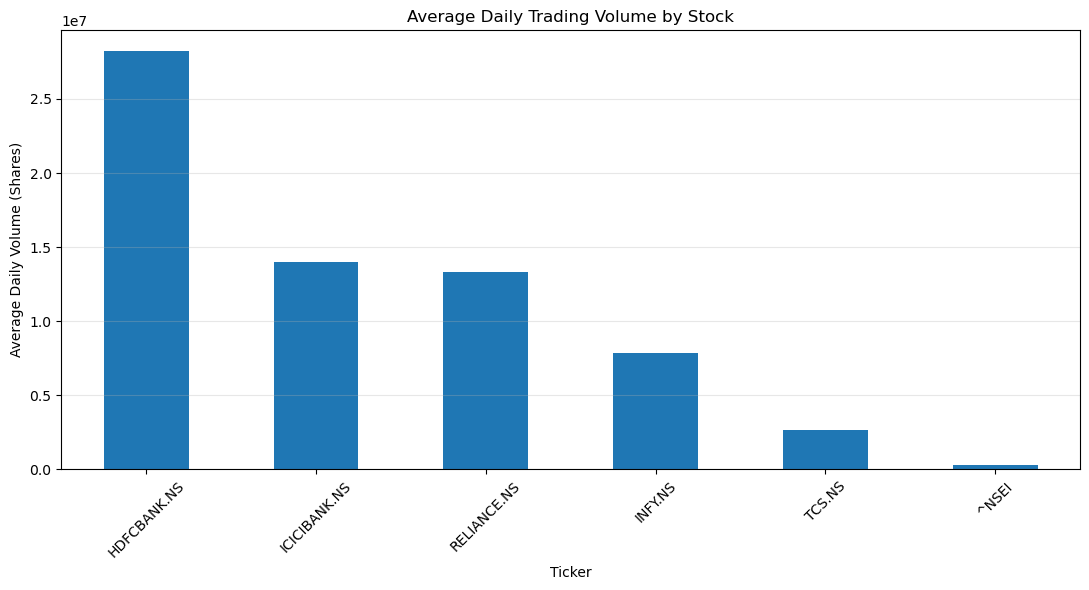

In [11]:
volume_data = (
    df.groupby("Ticker")["Volume"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Daily Trading Volume:")
print(volume_data)

plt.figure(figsize=(11, 6))

volume_data.plot(kind="bar")

plt.title("Average Daily Trading Volume by Stock")
plt.xlabel("Ticker")
plt.ylabel("Average Daily Volume (Shares)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
monthly_prices = (
    df.set_index("Date")
    .groupby("Ticker")["Close"]
    .resample("ME")
    .last()
    .reset_index()
)

print(monthly_prices.head(10))

        Ticker       Date       Close
0  HDFCBANK.NS 2021-10-31  740.613464
1  HDFCBANK.NS 2021-11-30  698.830200
2  HDFCBANK.NS 2021-12-31  692.209351
3  HDFCBANK.NS 2022-01-31  695.157227
4  HDFCBANK.NS 2022-02-28  667.340576
5  HDFCBANK.NS 2022-03-31  687.974976
6  HDFCBANK.NS 2022-04-30  647.852539
7  HDFCBANK.NS 2022-05-31  657.444214
8  HDFCBANK.NS 2022-06-30  638.060974
9  HDFCBANK.NS 2022-07-31  678.862793


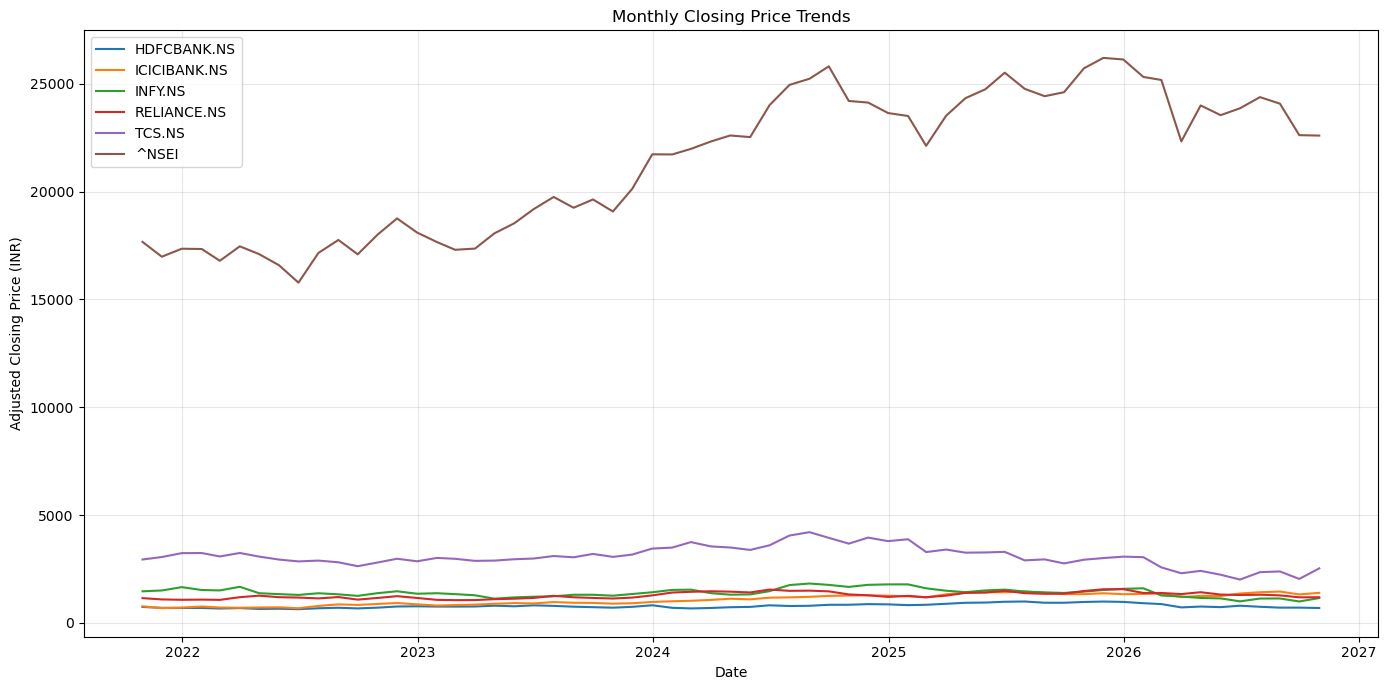

In [13]:
plt.figure(figsize=(14, 7))

for ticker in monthly_prices["Ticker"].unique():
    stock = monthly_prices[
        monthly_prices["Ticker"] == ticker
    ]
    
    plt.plot(
        stock["Date"],
        stock["Close"],
        label=ticker,
        linewidth=1.5
    )

plt.title("Monthly Closing Price Trends")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
Path("data/processed").mkdir(parents=True, exist_ok=True)

monthly_prices.to_csv(
    "data/processed/monthly_stock_prices.csv",
    index=False
)

df.to_csv(
    "data/processed/stock_market_eda.csv",
    index=False
)

print("EDA datasets saved successfully!")

EDA datasets saved successfully!
